# 02 · Cleaning, Preprocessing, Label Fusion & Validation Split

Builds on the findings of `01_data_exploration`:

1. **Cleaning**: which annotations/images to drop or fix
2. **Preprocessing**: limb-darkening correction and background flattening, *measured*, not assumed
3. **Label fusion**: how to use the 2–3 annotation sets per observation (each / union / vote / soft)
4. **Validation split**: grouped by time window, stratified by site → `artifacts/folds.csv`

In [1]:
# --- Setup: works both locally and on Kaggle ---
import os, sys
from pathlib import Path

IN_KAGGLE = os.path.exists("/kaggle/input")

if IN_KAGGLE:
    # Pull the shared src/ code from GitHub (requires Internet ON in notebook settings)
    if not Path("/kaggle/working/COS711-A2").exists():
        !git clone -q https://github.com/AryanMohanlall/COS711-A2.git /kaggle/working/COS711-A2
    ROOT = Path("/kaggle/working/COS711-A2")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(ROOT))

from src.data import get_data_dir
DATA_DIR = get_data_dir()
print("Kaggle:", IN_KAGGLE, "| data dir:", DATA_DIR)

Kaggle: False | data dir: C:\Users\aryan\OneDrive\Documents\COS711\A2\COS711-A2\data\MAGFiLO_1.0_Kaggle_2026


In [2]:
import itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from tqdm.auto import tqdm

from src.data import SITES, load_annotations, load_image, instance_mask_for
from src.preprocess import preprocess, disk_mask
from src.labels import fuse_instance_masks, soft_label
from src.split import make_folds
from src.metrics import panoptic_quality, match_instances

FIG_DIR = ROOT / "figures" / "02"
ART_DIR = ROOT / "artifacts"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
SITE_ORDER = list(SITES)

images, anns = load_annotations(DATA_DIR)
img_stats = pd.read_csv(ART_DIR / "image_stats.csv")      # from notebook 01 (disk geometry, outlier scores)
inst_stats = pd.read_csv(ART_DIR / "instance_stats.csv")
disk = img_stats.set_index("obs")[["cx", "cy", "radius"]]
degraded = set(img_stats.loc[img_stats.outlier_score > 5, "obs"])
sets_per_obs = images.groupby("obs").size()
print(f"{images.obs.nunique()} observations, {len(images)} annotation sets, {len(anns)} filaments; "
      f"{len(degraded & set(images.obs))} train observations flagged degraded")

C:\Users\aryan\OneDrive\Documents\COS711\A2\COS711-A2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


707 observations, 1154 annotation sets, 8199 filaments; 74 train observations flagged degraded


## 1. Cleaning

Notebook 01 found the annotations geometrically clean. Remaining candidates:
- polygons with a tiny area (likely accidental clicks)
- instances overlapping another instance of the same set
- degraded images (halo / haze / gradients): **kept**, because the test set contains the same kinds
  of image (26 of 180 test images flagged), so the model must learn to handle them.

Tiny instances (< 20 px): 1
Instances overlapping another in the same set: 18 in 9 sets, median overlap 6 px of median area 735 px


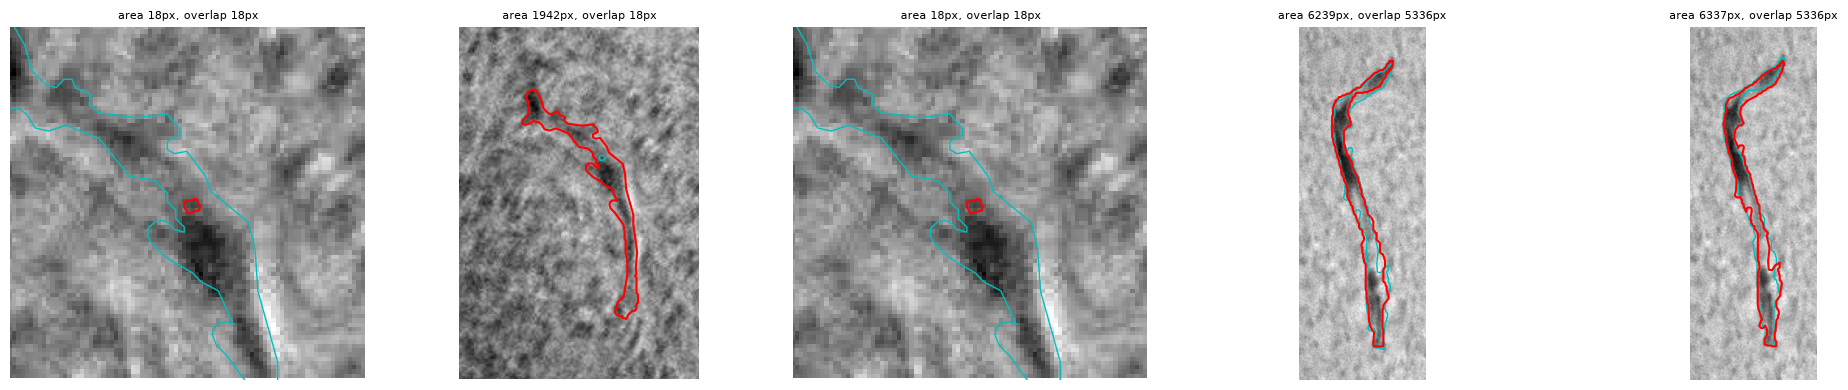

In [3]:
tiny = inst_stats[inst_stats.area_px < 20]
overl = inst_stats[inst_stats.overlap_px > 0]
print(f"Tiny instances (< 20 px): {len(tiny)}")
print(f"Instances overlapping another in the same set: {len(overl)} in {overl.image_id.nunique()} sets, "
      f"median overlap {overl.overlap_px.median():.0f} px of median area {overl.area_px.median():.0f} px")

fig, axes = plt.subplots(1, 1 + min(4, len(overl)), figsize=(4 * (1 + min(4, len(overl))), 4))
def show_instance(ax, ann_id, title):
    a = anns.loc[anns.id == ann_id].iloc[0]
    img = load_image(images.loc[images.image_id == a.image_id, "path"].iloc[0])
    others = anns[(anns.image_id == a.image_id) & (anns.id != ann_id)]
    x0, y0 = np.maximum(a.polygon.min(0).astype(int) - 40, 0)
    x1, y1 = a.polygon.max(0).astype(int) + 40
    ax.imshow(img[y0:y1, x0:x1], cmap="gray")
    for p in others.polygon:
        ax.plot(*(np.vstack([p, p[:1]]) - [x0, y0]).T, "c-", lw=1)
    ax.plot(*(np.vstack([a.polygon, a.polygon[:1]]) - [x0, y0]).T, "r-", lw=1.5)
    ax.set_xlim(0, x1 - x0); ax.set_ylim(y1 - y0, 0); ax.set_title(title, fontsize=8); ax.set_axis_off()

for ax, (_, r) in zip(axes, pd.concat([tiny, overl.head(4)]).iterrows()):
    show_instance(ax, r.ann_id, f"area {r.area_px}px, overlap {r.overlap_px}px")
plt.tight_layout(); savefig("cleaning_candidates"); plt.show()

In [4]:
# Decision: drop tiny polygons; keep overlapping instances (overlaps are small and the filaments are real).
# When rasterising, the later instance wins the overlapping pixels (src.data.instance_mask).
excluded = tiny[["ann_id", "image_id"]].assign(reason="area < 20 px")
excluded.to_csv(ART_DIR / "excluded_annotations.csv", index=False)
anns_clean = anns[~anns.id.isin(excluded.ann_id)].reset_index(drop=True)
print(f"Annotations after cleaning: {len(anns_clean)} (dropped {len(anns) - len(anns_clean)})")

Annotations after cleaning: 8198 (dropped 1)


## 2. Preprocessing

`src.preprocess.preprocess(img, mode)`:

| mode | what it does |
|---|---|
| `raw`  | intensity / 255 |
| `limb` | divide by the image's own radial median profile (removes limb darkening; quiet Sun ≈ 1), off-disk → 1 |
| `full` | `limb` + divide by a ~500 px median-filtered background (removes haze and illumination gradients), off-disk → 1 |

Pixels beyond 0.985 R are set to 1 in `limb`/`full`: dividing by the radial profile turns the 1–2 px
bright limb rim into a ring artefact there (measured: residual std jumps from ~0.08 to 0.4–0.6 beyond
0.985 R), while only 0.036% of annotated polygon vertices lie that far out.

The median filter window (~500 px) is ~40× the median filament width (12 px), so filaments do not leak
into the background estimate.

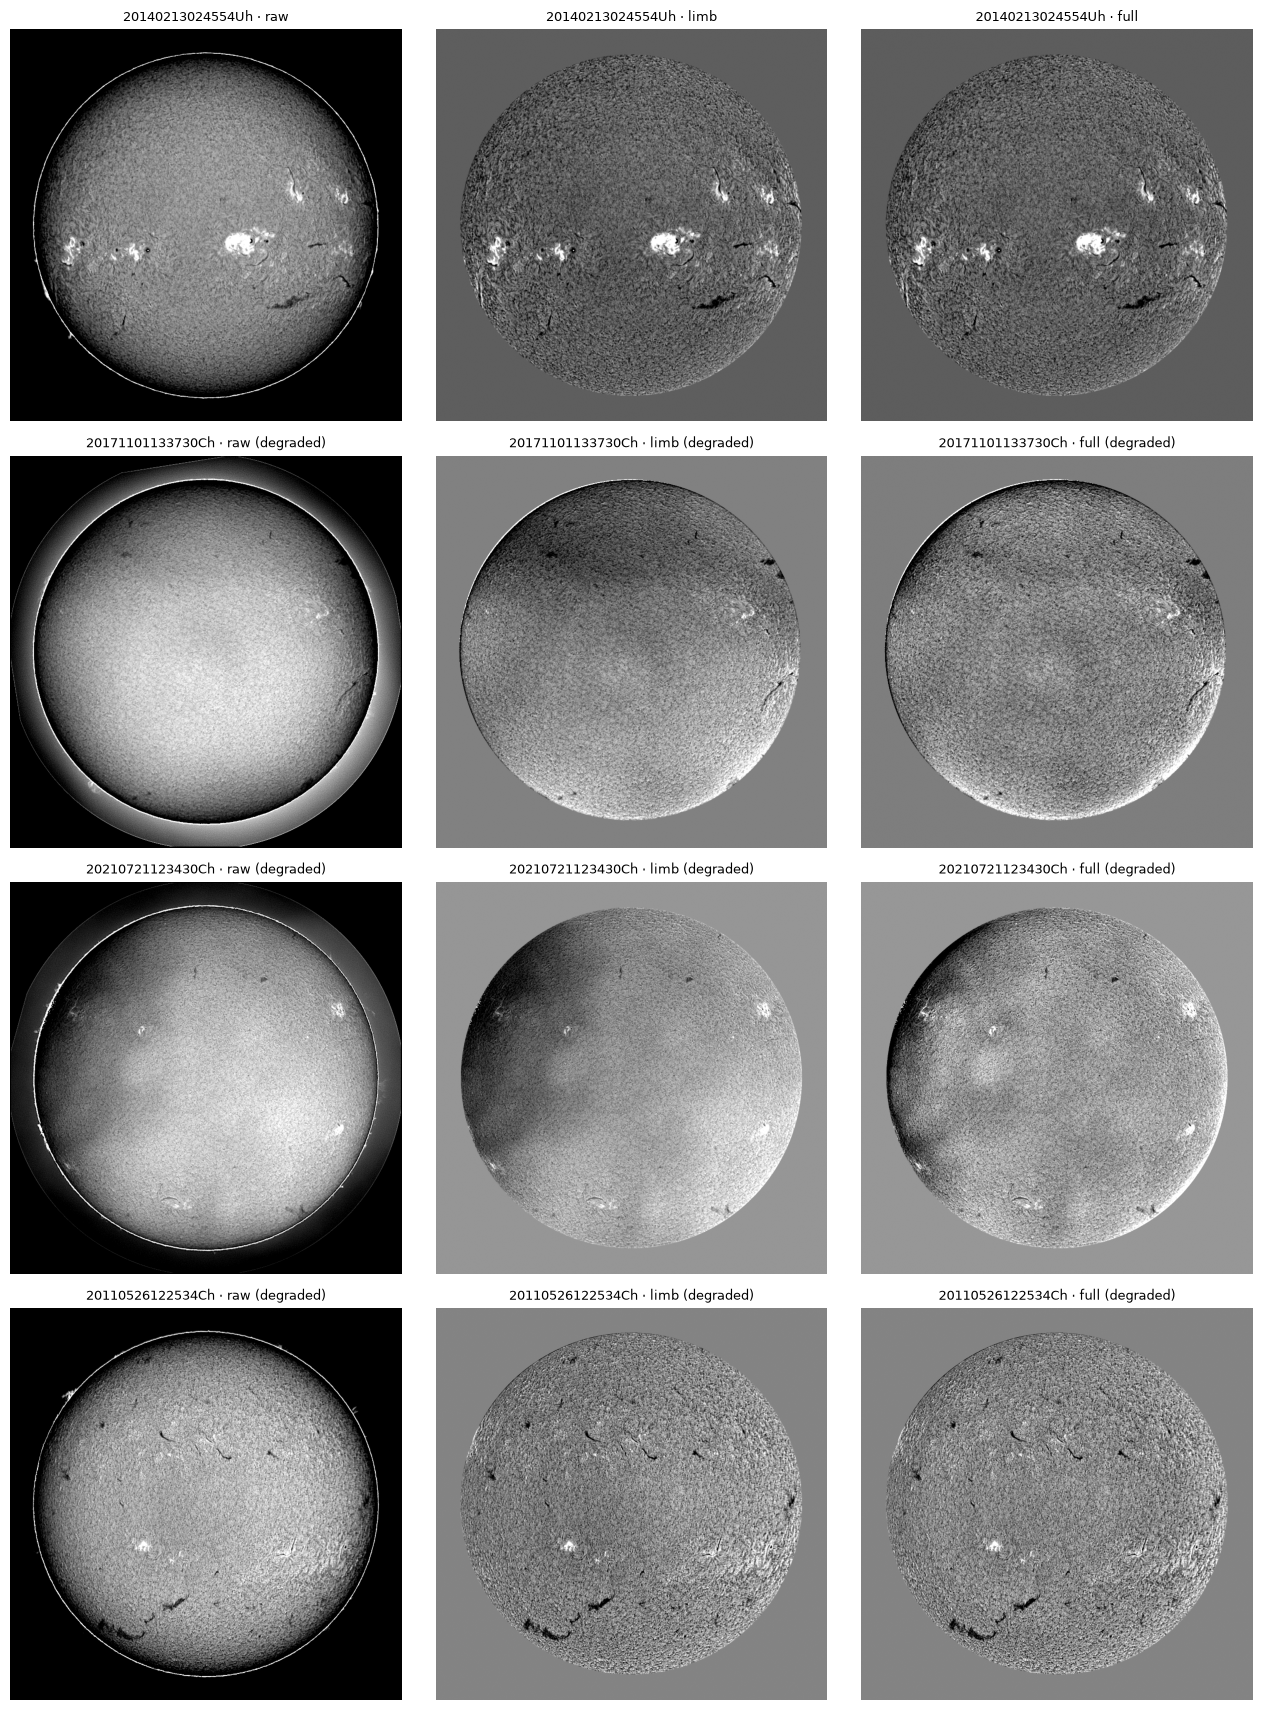

In [5]:
examples = ["20140213024554Uh"] + list(img_stats[(img_stats.split == "train") & (img_stats.outlier_score > 5)]
                                       .sort_values("outlier_score", ascending=False).obs.head(3))
modes = ["raw", "limb", "full"]
fig, axes = plt.subplots(len(examples), 3, figsize=(13, 4.3 * len(examples)))
for row, obs in zip(axes, examples):
    img = load_image(images.loc[images.obs == obs, "path"].iloc[0])
    for ax, m in zip(row, modes):
        x = preprocess(img, m, tuple(disk.loc[obs]))
        lo, hi = np.percentile(x[disk_mask(x.shape, *disk.loc[obs], 0.95)], [0.5, 99.5])
        ax.imshow(cv2.resize(x, (768, 768), interpolation=cv2.INTER_AREA), cmap="gray", vmin=lo, vmax=hi)
        ax.set_title(f"{obs} · {m}" + (" (degraded)" if obs in degraded else ""), fontsize=9); ax.set_axis_off()
plt.tight_layout(); savefig("preprocessing_examples"); plt.show()

### Does preprocessing make filaments easier to separate from the background?

For a site-stratified sample of training images, sample filament pixels (marked by any annotator)
and on-disk background pixels (marked by no annotator), then measure how well **one global intensity
threshold** separates them, as ROC AUC on pixel intensity (filaments are dark, so we score `-intensity`).

A pooled AUC across many images only gets high if intensities are comparable *between* images, which
is exactly what normalisation should achieve. Per-image AUC measures contrast *within* an image.

In [6]:
rng = np.random.default_rng(0)
sample_obs = (images.drop_duplicates("obs").groupby("site", group_keys=False)
              .apply(lambda g: g.sample(min(35, len(g)), random_state=0)).obs.tolist())
N_FG, N_BG = 1500, 6000
pix = {m: {"fg": [], "bg": []} for m in modes}
per_image = []

for obs in tqdm(sample_obs):
    ids = images.loc[images.obs == obs, "image_id"]
    any_fg = np.any([instance_mask_for(i, anns_clean) > 0 for i in ids], axis=0)
    img = load_image(images.loc[images.obs == obs, "path"].iloc[0])
    geo = tuple(disk.loc[obs])
    bg_region = disk_mask(img.shape, *geo, 0.97) & ~cv2.dilate(any_fg.astype(np.uint8), np.ones((15, 15))).astype(bool)
    fg_idx = np.flatnonzero(any_fg); bg_idx = np.flatnonzero(bg_region)
    fg_s = rng.choice(fg_idx, min(N_FG, len(fg_idx)), replace=False)
    bg_s = rng.choice(bg_idx, N_BG, replace=False)
    row = {"obs": obs, "site": obs[14], "degraded": obs in degraded}
    for m in modes:
        x = preprocess(img, m, geo).ravel()
        pix[m]["fg"].append(x[fg_s]); pix[m]["bg"].append(x[bg_s])
        y = np.r_[np.ones(len(fg_s)), np.zeros(len(bg_s))]
        row[f"auc_{m}"] = roc_auc_score(y, -np.r_[x[fg_s], x[bg_s]])
    per_image.append(row)
per_image = pd.DataFrame(per_image)

pooled = {}
for m in modes:
    fg, bg = np.concatenate(pix[m]["fg"]), np.concatenate(pix[m]["bg"])
    pooled[m] = roc_auc_score(np.r_[np.ones(len(fg)), np.zeros(len(bg))], -np.r_[fg, bg])
res = pd.DataFrame({
    "pooled AUC (one global threshold)": pooled,
    "mean per-image AUC": {m: per_image[f"auc_{m}"].mean() for m in modes},
    "per-image AUC, degraded only": {m: per_image.loc[per_image.degraded, f"auc_{m}"].mean() for m in modes},
})
print(f"{len(sample_obs)} images ({per_image.degraded.sum()} degraded)")
res

  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 1/210 [00:00<01:29,  2.33it/s]

  1%|          | 2/210 [00:00<01:26,  2.40it/s]

  1%|▏         | 3/210 [00:01<01:31,  2.27it/s]

  2%|▏         | 4/210 [00:01<01:28,  2.33it/s]

...

100%|█████████▉| 209/210 [01:39<00:00,  2.06it/s]

100%|██████████| 210/210 [01:40<00:00,  1.84it/s]

100%|██████████| 210/210 [01:40<00:00,  2.09it/s]

210 images (24 degraded)


,pooled AUC (one global threshold),mean per-image AUC,"per-image AUC, degraded only"
raw,0.659,0.661,0.607
limb,0.779,0.783,0.753
full,0.795,0.798,0.786


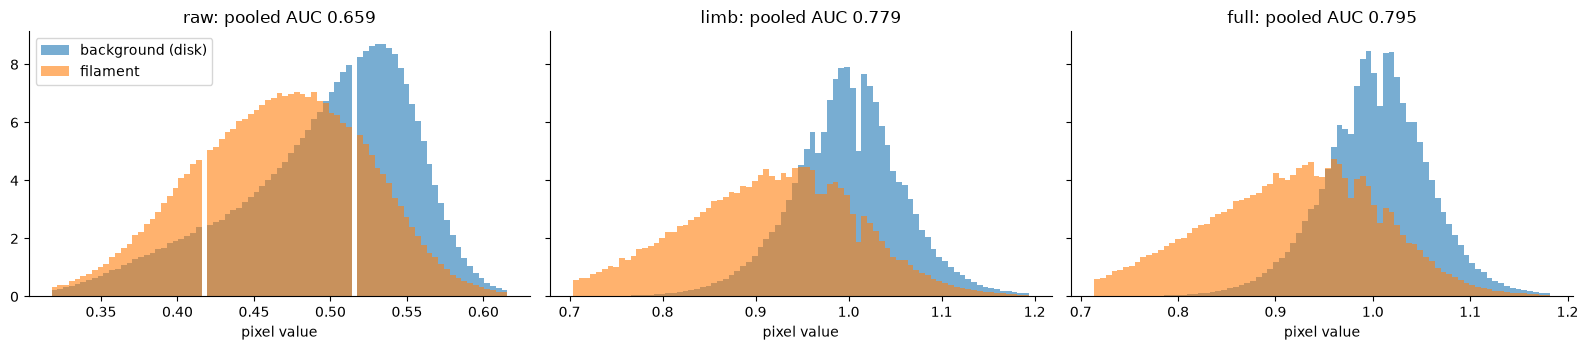

,auc_raw,auc_limb,auc_full
site,,,
B,0.668,0.784,0.797
C,0.650,0.749,0.775
L,0.670,0.786,0.811
M,0.665,0.788,0.807
T,0.636,0.791,0.799
U,0.678,0.799,0.801


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6), sharey=True)
for ax, m in zip(axes, modes):
    fg, bg = np.concatenate(pix[m]["fg"]), np.concatenate(pix[m]["bg"])
    lo, hi = np.percentile(np.r_[fg, bg], [0.5, 99.5])
    bins = np.linspace(lo, hi, 80)
    ax.hist(bg, bins, density=True, alpha=0.6, label="background (disk)")
    ax.hist(fg, bins, density=True, alpha=0.6, label="filament")
    ax.set_title(f"{m}: pooled AUC {pooled[m]:.3f}"); ax.set_xlabel("pixel value")
axes[0].legend(); plt.tight_layout(); savefig("preprocessing_separability"); plt.show()

per_image.groupby("site")[[f"auc_{m}" for m in modes]].mean().reindex(SITE_ORDER)

## 3. Label fusion

For the 296 observations with 2–3 annotation sets, compare the candidate training labels
(`src.labels`):

- **each**: every annotation set is a separate training sample (the model sees conflicting targets)
- **union**: any annotator → filament (most complete; boundaries widest)
- **vote**: ≥ ⌈n/2⌉ annotators (n=3 → 2 of 3; n=2 → same as union)
- **soft**: fraction of annotators per pixel, for soft-target losses

Fused instances are connected components, so a fused label can **merge** filaments that one annotator
kept separate. The *actual* comparison is training a model on each (notebook 04), validated against
every individual annotation set. Here we characterise the labels themselves.

In [8]:
multi_obs = sets_per_obs[sets_per_obs > 1].index
rows = []
for obs in tqdm(multi_obs):
    ids = list(images.loc[images.obs == obs, "image_id"])
    masks = [instance_mask_for(i, anns_clean) for i in ids]
    fused = {m: fuse_instance_masks(masks, m) for m in ("union", "vote")}
    row = {"obs": obs, "n_sets": len(masks), "n_inst_each": np.mean([m.max() for m in masks]),
           "fg_each": np.mean([(m > 0).sum() for m in masks])}
    for name, f in fused.items():
        row[f"n_inst_{name}"] = int(f.max())
        row[f"fg_{name}"] = int((f > 0).sum())
        # fused components containing >= 2 separate instances from one annotator = merges
        merged = set()
        for m in masks:
            both = (f > 0) & (m > 0)
            pairs = np.unique(np.stack([f[both], m[both]]), axis=1)   # (fused id, annotator id) pairs
            ids, counts = np.unique(pairs[0], return_counts=True)
            merged |= set(ids[counts >= 2].tolist())
        row[f"merged_{name}"] = len(merged)
        # how well does the fused label agree with each individual annotator?
        row[f"pq_vs_sets_{name}"] = np.mean([panoptic_quality(m, f)["pq"] for m in masks])
    # baseline: one annotator vs the others
    row["pq_vs_sets_each"] = np.mean([panoptic_quality(a, b)["pq"] for a, b in itertools.permutations(masks, 2)])
    rows.append(row)
fusion = pd.DataFrame(rows)
fusion.to_csv(ART_DIR / "fusion_stats.csv", index=False)

summary = pd.DataFrame({
    m: {"filaments per image": fusion[f"n_inst_{m}"].mean(),
        "filament pixels (× single set)": (fusion[f"fg_{m}"] / fusion.fg_each).mean() if m != "each" else 1.0,
        "fused components that merge ≥2 filaments of one annotator": fusion[f"merged_{m}"].sum() if m != "each" else 0,
        "mean PQ vs individual annotators": fusion[f"pq_vs_sets_{m}"].mean()}
    for m in ("each", "union", "vote")}).T
summary

  0%|          | 0/296 [00:00<?, ?it/s]

  0%|          | 1/296 [00:00<04:24,  1.11it/s]

  1%|          | 2/296 [00:01<04:29,  1.09it/s]

  1%|          | 3/296 [00:02<04:27,  1.10it/s]

  1%|▏         | 4/296 [00:03<03:39,  1.33it/s]

...

 99%|█████████▉| 294/296 [03:54<00:01,  1.21it/s]

100%|█████████▉| 295/296 [03:55<00:00,  1.10it/s]

100%|██████████| 296/296 [03:56<00:00,  1.03it/s]

100%|██████████| 296/296 [03:56<00:00,  1.25it/s]

,filaments per image,filament pixels (× single set),fused components that merge ≥2 filaments of one annotator,mean PQ vs individual annotators
each,6.740,1.000,0.0,0.364
union,7.953,1.509,173.0,0.639
vote,7.145,1.108,112.0,0.671


In [9]:
print("By number of sets:")
fusion.groupby("n_sets")[["n_inst_each", "n_inst_union", "n_inst_vote", "pq_vs_sets_each",
                          "pq_vs_sets_union", "pq_vs_sets_vote"]].mean()

By number of sets:


,n_inst_each,n_inst_union,n_inst_vote,pq_vs_sets_each,pq_vs_sets_union,pq_vs_sets_vote
n_sets,,,,,,
2,6.852,7.731,7.731,0.372,0.712,0.712
3,6.634,8.166,6.583,0.357,0.570,0.631


### Fair test: does combining annotators predict an unseen annotator better?

The table above is biased: each fused label *contains* the annotator it is scored against.
Leave-one-out instead: for observations with 3 sets, hold one set out, build a label from the
other two, and score it against the held-out set (PQ). For two remaining sets, `vote` (≥ 1 of 2)
equals `union`, so the comparison is single annotator vs union vs intersection of the other two.

In [10]:
loo = []
for obs in tqdm(sets_per_obs[sets_per_obs == 3].index):
    ids = list(images.loc[images.obs == obs, "image_id"])
    masks = [instance_mask_for(i, anns_clean) for i in ids]
    for h in range(3):
        held, rest = masks[h], [m for j, m in enumerate(masks) if j != h]
        loo.append({
            "obs": obs,
            "single annotator": np.mean([panoptic_quality(held, r)["pq"] for r in rest]),
            "union of other two": panoptic_quality(held, fuse_instance_masks(rest, "union"))["pq"],
            "intersection of other two": panoptic_quality(held, fuse_instance_masks(rest, "intersection"))["pq"],
        })
loo = pd.DataFrame(loo)
loo.to_csv(ART_DIR / "fusion_leave_one_out.csv", index=False)
cols = ["single annotator", "union of other two", "intersection of other two"]
res_loo = loo[cols].agg(["mean", "std"]).T
# paired comparison per observation (same held-out annotator)
res_loo["Δ vs single (mean)"] = [0.0] + [(loo[c] - loo["single annotator"]).mean() for c in cols[1:]]
res_loo

  0%|          | 0/151 [00:00<?, ?it/s]

  1%|          | 1/151 [00:01<02:38,  1.06s/it]

  1%|▏         | 2/151 [00:02<02:36,  1.05s/it]

  2%|▏         | 3/151 [00:03<02:37,  1.07s/it]

  3%|▎         | 4/151 [00:04<02:35,  1.06s/it]

...

 99%|█████████▊| 149/151 [03:54<00:03,  1.84s/it]

 99%|█████████▉| 150/151 [03:56<00:01,  1.86s/it]

100%|██████████| 151/151 [03:58<00:00,  1.85s/it]

100%|██████████| 151/151 [03:58<00:00,  1.58s/it]

,mean,std,Δ vs single (mean)
single annotator,0.357,0.141,0.000
union of other two,0.360,0.162,0.002
intersection of other two,0.354,0.176,-0.003


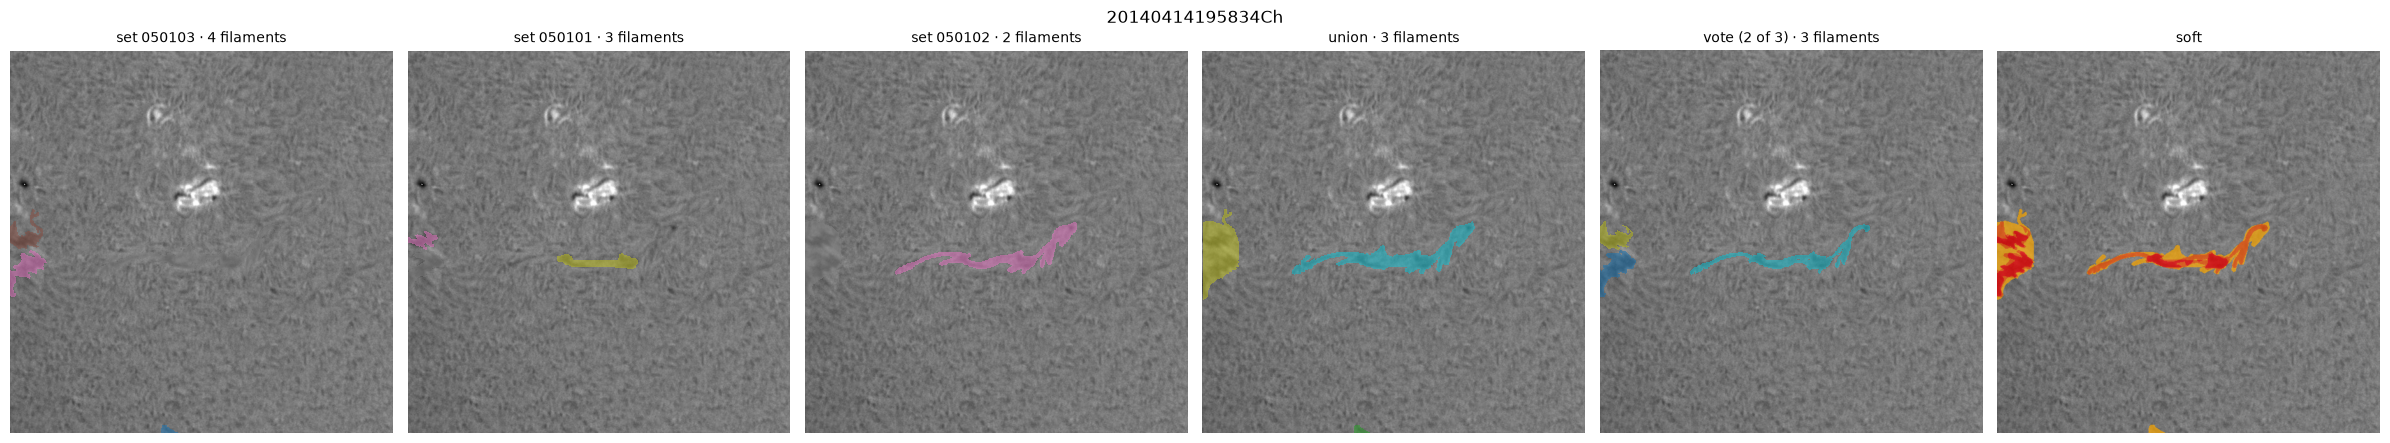

In [11]:
# Visual example: an observation with 3 sets and the fused labels, zoomed on a region with disagreement
obs = fusion[fusion.n_sets == 3].sort_values("pq_vs_sets_each").obs.iloc[len(fusion[fusion.n_sets == 3]) // 4]
ids = list(images.loc[images.obs == obs, "image_id"])
masks = [instance_mask_for(i, anns_clean) for i in ids]
img = load_image(images.loc[images.obs == obs, "path"].iloc[0])
panels = [(f"set {i.split('-')[0]}", m) for i, m in zip(ids, masks)] + \
         [("union", fuse_instance_masks(masks, "union")), ("vote (2 of 3)", fuse_instance_masks(masks, "vote")),
          ("soft", soft_label(masks))]
fg = np.any([m > 0 for m in masks], axis=0)
ys, xs = np.nonzero(fg)
cy, cx = int(np.median(ys)), int(np.median(xs))
y0, x0 = max(cy - 300, 0), max(cx - 300, 0)
crop = (slice(y0, y0 + 600), slice(x0, x0 + 600))

fig, axes = plt.subplots(1, 6, figsize=(24, 4.5))
for ax, (title, m) in zip(axes, panels):
    ax.imshow(img[crop], cmap="gray")
    if title == "soft":
        ax.imshow(np.ma.masked_equal(m[crop], 0), cmap="autumn_r", alpha=0.7, vmin=0, vmax=1)
    else:
        ax.imshow(np.ma.masked_equal(m[crop], 0) % 10, cmap="tab10", alpha=0.55, vmin=0, vmax=9, interpolation="nearest")
        title += f" · {len(np.unique(m[crop])) - 1} filaments"
    ax.set_title(title, fontsize=10); ax.set_axis_off()
plt.suptitle(obs); plt.tight_layout(); savefig("fusion_example"); plt.show()

## 4. Validation split

- unit = **observation** (all annotation sets of an observation stay together)
- observations less than 48 h apart are chained into one **time group**; groups never cross folds
  (this covers the near-simultaneous multi-site pairs found in notebook 01)
- 5 folds, **stratified by site**, so each fold contains every GONG site
- fold 0 is the default hold-out; full cross-validation when the budget allows (means ± std over folds)

In [12]:
obs_df = images.groupby("obs").agg(time=("time", "first"), site=("site", "first"),
                                   n_sets=("image_id", "size")).reset_index()
folds = make_folds(obs_df, n_splits=5, max_gap="48h", seed=42)
folds["degraded"] = folds.obs.isin(degraded)
n_inst = anns_clean.groupby("obs").size()
folds["n_instances_all_sets"] = folds.obs.map(n_inst)

# Integrity checks
assert folds.groupby("group").fold.nunique().max() == 1, "a time group crosses folds"
assert (folds.fold >= 0).all()
assert images.merge(folds[["obs", "fold"]], on="obs").groupby("obs").fold.nunique().max() == 1

print(f"{folds.group.nunique()} time groups; largest has {folds.groupby('group').size().max()} observations")
folds.to_csv(ART_DIR / "folds.csv", index=False)

per_fold = folds.groupby("fold").agg(observations=("obs", "size"), annotation_sets=("n_sets", "sum"),
                                     instances=("n_instances_all_sets", "sum"), degraded=("degraded", "sum"),
                                     multi_set_obs=("n_sets", lambda s: (s > 1).sum()))
per_fold.join(pd.crosstab(folds.fold, folds.site))

426 time groups; largest has 8 observations


,observations,annotation_sets,instances,degraded,multi_set_obs,B,C,L,M,T,U
fold,,,,,,,,,,,
0,142,229,1541,16,59,24,25,26,25,22,20
1,140,224,1435,16,57,23,25,25,25,22,20
2,141,240,1860,13,64,24,25,25,25,22,20
3,142,228,1574,9,60,24,25,25,25,22,21
4,142,233,1788,20,56,23,25,26,25,22,21


Closest train↔val pair per fold (hours): [48. 48. 48. 48. 48.]


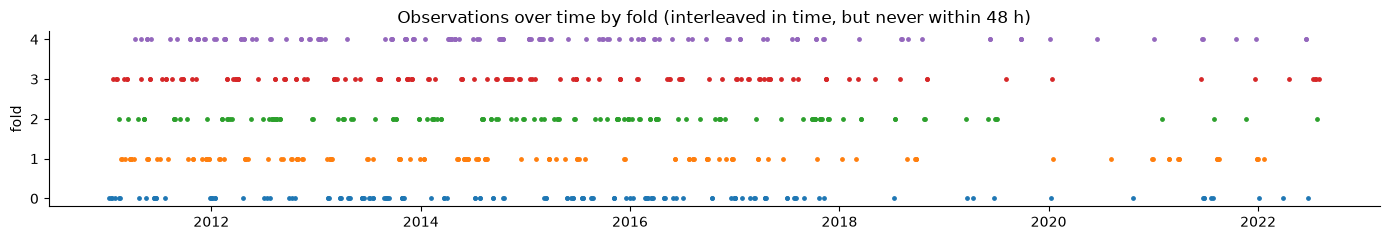

In [13]:
# Minimum time between any validation observation and the closest training observation, per fold
gaps = []
for f in range(5):
    v = folds.loc[folds.fold == f, "time"].values[:, None]
    t = folds.loc[folds.fold != f, "time"].values[None, :]
    gaps.append(np.abs(v - t).min() / np.timedelta64(1, "h"))
print("Closest train↔val pair per fold (hours):", np.round(gaps, 1))

fig, ax = plt.subplots(figsize=(14, 2.5))
for f in range(5):
    t = folds.loc[folds.fold == f, "time"]
    ax.scatter(t, np.full(len(t), f), s=6)
ax.set(yticks=range(5), ylabel="fold", title="Observations over time by fold (interleaved in time, but never within 48 h)")
plt.tight_layout(); savefig("folds_timeline"); plt.show()

## Summary

| Step | Result | Decision |
|---|---|---|
| **Cleaning** | 1 polygon < 20 px; 18 instances overlap another in the same set (median 6 px overlap). 74 train / 26 test images degraded. | Drop the tiny polygon (`artifacts/excluded_annotations.csv`). Keep overlaps (later instance wins). **Keep degraded images**: the test set has them too. |
| **Preprocessing** | Pooled pixel AUC (filament vs background, one global threshold): **raw 0.659 → limb 0.779 → full 0.795**. On degraded images: **0.607 → 0.753 → 0.786**. Improves at every site. | Use `preprocess(mode="full")` as the default model input; keep `raw` as an ablation in notebook 04 (a CNN may learn some normalisation itself, so test it). ~125 ms/image. |
| | Remaining limitations: faint limb crescent where the disk fit is a few px off; strong haze only partly removed. | Augment with illumination gradients/haze so the model tolerates the residue. |
| **Label fusion** | Scored against the annotators they were built from, fused labels look much better (PQ 0.64–0.67 vs 0.36), but that is circular. **Leave-one-out** (predict an unseen 3rd annotator): single 0.357, union of two 0.360, intersection 0.354, so **no real gain**. Union also merges 173 pairs of separate filaments into one component, vote 112. | Fusion does not produce a "truer" label in PQ terms, and merging hurts PQ. Default: **`each`** (every set a separate sample: more data, disagreement acts as label noise). Compare against `vote` and soft labels in notebook 04. |
| **Validation split** | 426 time groups (max 8 obs), 5 folds of 140–142 observations, every site in every fold (20–26 obs each), degraded images in every fold (9–20). Closest train↔val pair: 48 h in every fold. | `artifacts/folds.csv`. Validate against **every individual annotation set** of a val observation (mean PQ), never a fused label. |
